In [ ]:
# Locate this checkout when launched from the repository or notebook folder.
from pathlib import Path
import sys
_REPOSITORY_ROOT = next(
    p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    if (p / "aerosandbox/__init__.py").is_file()
    and (p / "studies/TSher_Improvements").is_dir()
)
_STUDY_DIRECTORY = _REPOSITORY_ROOT / "studies/TSher_Improvements/aerodynamics"
for _path in [_REPOSITORY_ROOT, _STUDY_DIRECTORY]:
    if str(_path) not in sys.path:
        sys.path.insert(0, str(_path))


# Comparison and Validation — Conventional UAV

This companion to **01 - Comparison and Validation - Flying Wing** compares AeroBuildup,
VortexLatticeMethod, the branch's VortexLatticeViscous, NonlinearLiftingLine, and LiftingLine
against the archived **NASA FASER / Ultra Stick** aerodynamic database. This is a conventional
high-wing UAV with a horizontal tail and vertical fin.

**Status: preliminary comparison with experimental-derived data, using proxy geometry.**
The reference is a wind-tunnel-derived simulation table, not raw balance measurements.
The public Ultra Stick geometry is related to FASER but does not establish an exact match to
the tested article. The figures are useful for developing this validation workflow; their
errors cannot isolate solver accuracy from geometry and test-condition uncertainty.

No lift, drag, angle, or moment offsets are fitted to the reference. This study was generated
with Codex and still needs human review before use in an upstream contribution.

## Sources and comparison scope

- [Owens, Cox & Morelli (2006), *The FASER Project*](https://ntrs.nasa.gov/citations/20060022541)
  describes the aircraft and its wind-tunnel/flight-test program.
- [Morelli & DeLoach (2003), *Wind Tunnel Database Development*](https://ntrs.nasa.gov/citations/20030014297)
  describes an earlier FASER tunnel campaign at 2 psf dynamic pressure. That earlier aircraft
  configuration is not identical to the later geometry; its pressure is an **operating-point
  assumption here**, not recovered metadata for the MATLAB table.
- [University of Minnesota archived simulation library](https://dept.aem.umn.edu/~mettler/Courses/AEM%205333%20%28spring%202013%29/Matlab/Ultrastick%20Simulation/trunk/Simulation/Libraries/)
  supplies `FASER_Aero.mat`, `FASER_config.m`, and the interpolation library. We extract
  `C6_bas` at beta = 0: baseline coefficients without power, control, rate, or asymmetry increments.
  These processed table nodes have no supplied measurement uncertainties or Reynolds axis.
- [UASLab OpenFlightSim](https://github.com/UASLab/OpenFlightSim) supplies the related
  `UltraStick120.avl` lifting-surface geometry under its included MIT license. `sources.json`
  records the geometry revision, download URLs, and SHA-256 hashes.

The main sweep uses the **lifting surfaces only** for every solver. The reference includes
the aircraft body and test installation, so missing body/landing-gear/interference drag is
expected. All controls are neutral, beta and angular rates are zero, and no propeller model
is applied. The baseline table is not a claim that every physical propeller/installation
effect was removed in the experiment.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import os
import platform
import subprocess
import time
import warnings

import aerosandbox as asb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from IPython.display import display

# Run from this notebook's folder or from the repository root. No downloads are needed.
candidates = [
    Path('conventional_uav_validation_assets'),
    Path('studies/TSher_Improvements/aerodynamics/conventional_uav_validation_assets'),
]
assets = next((p.resolve() for p in candidates if (p / 'FASER_Aero.mat').is_file()), None)
if assets is None:
    raise FileNotFoundError('Run from the notebook folder or the AeroSandbox repository root.')
output_dir = assets / 'results'
output_dir.mkdir(exist_ok=True)
sources = json.loads((assets / 'sources.json').read_text())
for name, entry in sources['files'].items():
    actual = hashlib.sha256((assets / name).read_bytes()).hexdigest()
    if actual != entry['sha256']:
        raise ValueError(f'Source file changed: {name}. Review and update sources.json deliberately.')

plt.rcParams.update({'figure.dpi': 130, 'axes.grid': True, 'grid.alpha': 0.2})
pd.set_option('display.max_columns', 20)
pd.set_option('display.precision', 5)
print('Verified archived source hashes. Outputs:', output_dir)

Verified archived source hashes. Outputs: C:\Users\tsher\OneDrive\Documents\Aircraft_Design\Github\AeroSandbox\studies\TSher_Improvements\conventional_uav_validation_assets\results


## Extract the archived reference

The table's own `dim` field specifies `[alpha] × [beta] × [CD, CY, CL, Cl, Cm, Cn]`.
Uppercase `CL` is lift; lowercase `Cl` is rolling moment. Nothing is digitized from a plot.
The complete extraction, including the high-angle range, is saved to CSV. Only −3° through
22° is used in the main comparison, with stall-window metrics restricted to −3° through 18°.

In [2]:
database = loadmat(assets / 'FASER_Aero.mat', simplify_cells=True)
baseline = database['C6_bas']
alpha_reference = np.asarray(baseline['alpha'], dtype=float).ravel()
beta_reference = np.asarray(baseline['beta'], dtype=float).ravel()
coefficients = np.asarray(baseline['data'], dtype=float)
assert coefficients.shape == (len(alpha_reference), len(beta_reference), 6)
assert np.all(np.diff(alpha_reference) > 0)
beta_zero = np.flatnonzero(np.isclose(beta_reference, 0))
assert len(beta_zero) == 1
reference = pd.DataFrame(
    coefficients[:, beta_zero[0], :], columns=['CD', 'CY', 'CL', 'Cl', 'Cm', 'Cn']
)
reference.insert(0, 'beta', 0.0)
reference.insert(0, 'alpha', alpha_reference)
assert np.isfinite(reference.to_numpy()).all()
assert (reference.CD > 0).all()
reference.to_csv(output_dir / 'faser_reference_beta0.csv', index=False)
reference_comparison = reference[reference.alpha.between(-3, 22)].reset_index(drop=True)
print('Table metadata:', baseline['dim'])
display(reference_comparison)

Table metadata: Dimensions are [alpha]x[beta]x[CD,CY,CL,Cl,Cm,Cn]


,alpha,beta,CD,CY,CL,Cl,Cm,Cn
0,-3.00000,0.00000,0.05339,0.00000,-0.27774,0.00000,-0.00499,0.00000
1,2.00000,0.00000,0.03695,0.00000,0.10640,0.00000,-0.03222,0.00000
2,7.00000,0.00000,0.04448,0.00000,0.49295,0.00000,-0.06616,0.00000
3,12.00000,0.00000,0.08933,0.00000,0.86655,0.00000,-0.12635,0.00000
4,13.75000,0.00000,0.12242,0.00000,0.98061,0.00000,-0.16509,0.00000
5,14.50000,0.00000,0.14402,0.00000,1.00647,0.00000,-0.19555,0.00000
6,15.25000,0.00000,0.19486,0.00000,0.96134,0.00000,-0.26596,0.00000
7,15.50000,0.00000,0.21078,0.00000,0.94392,0.00000,-0.28814,0.00000
8,17.00000,0.00000,0.25577,0.00000,0.97511,0.00000,-0.35348,0.00000
9,18.00000,0.00000,0.28901,0.00000,0.98922,0.00000,-0.38628,0.00000


## Reconstruct the related aircraft geometry

All main-wing and horizontal-tail section coordinates and airfoil assignments come from the
included AVL file. We keep its tip shape and span; we do not rescale it to fit the reference.
The AVL fin lists its span along y, so we stand that surface vertically by mapping its span
coordinate to z. We explicitly use NACA 0005 at both fin stations (the root has no explicit
airfoil record in the source). This is a reconstruction assumption.

Coefficient normalization uses the archived FASER configuration: S = 0.769237171 m²,
b = 1.917192 m, c = 0.433578 m. These differ slightly from the AVL references. Moments
use the AVL file's reference point [0.469, 0, 0.053] m. The archive's moment origin cannot be
reconciled unambiguously with that geometry origin, so **Cm is diagnostic only** and is not
included in error rankings. Neither aircraft is trimmed during this alpha sweep.

,surface,area_m2,span_m
0,Main wing,0.77742,1.9304
1,Horizontal tail,0.19112,0.7048
2,Vertical tail,0.06304,0.2159


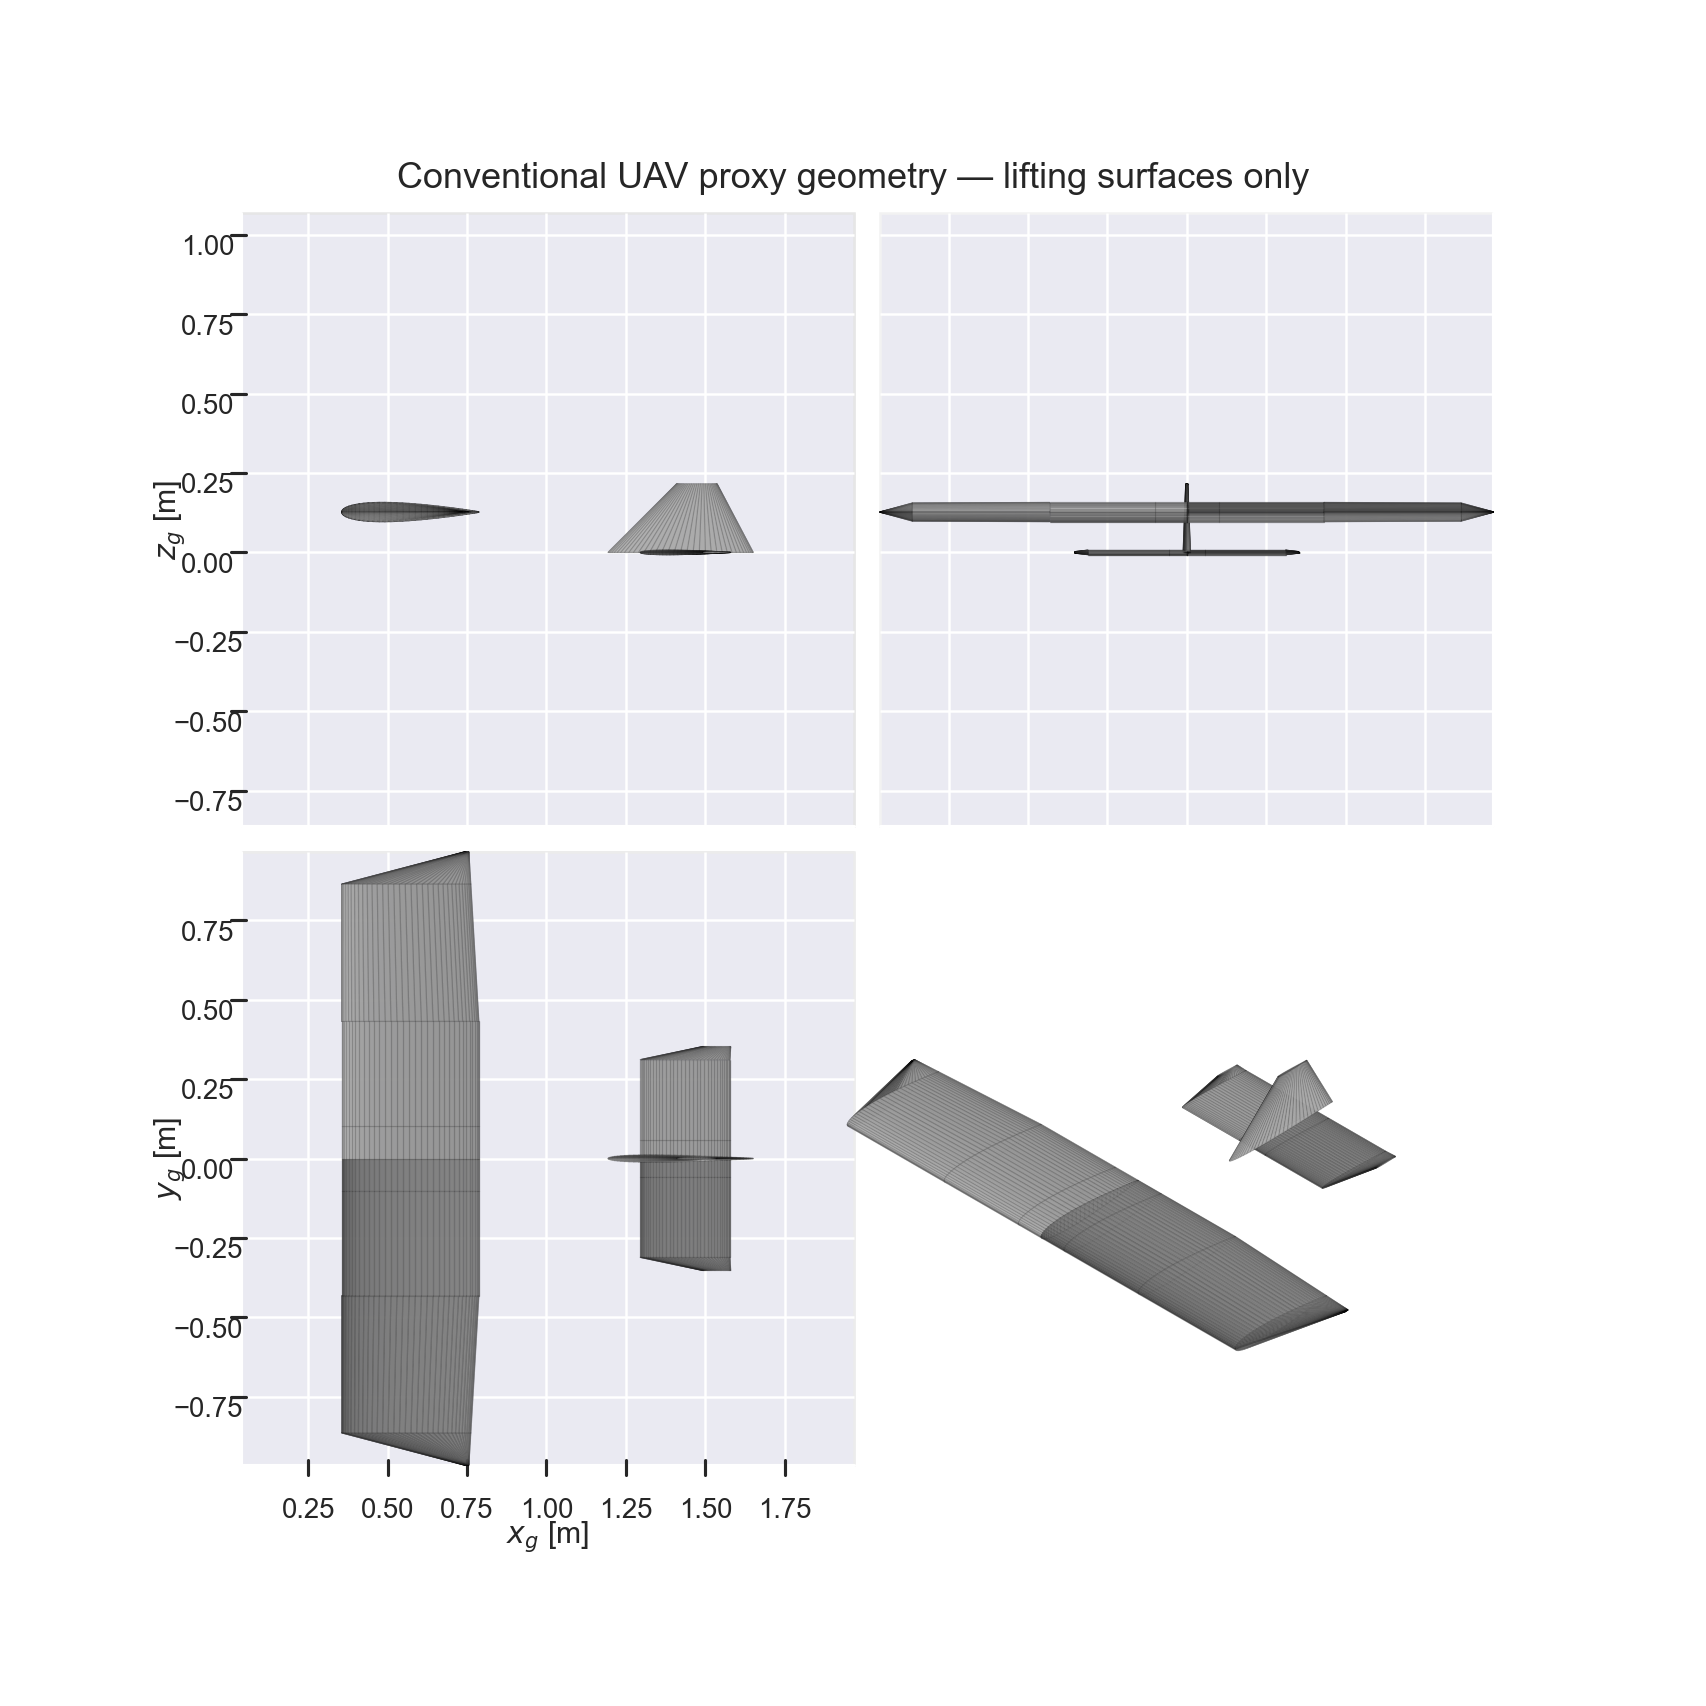

In [3]:
S_REF, B_REF, C_REF = 0.769237171, 1.917192, 0.433578
XYZ_REF = [0.469, 0.0, 0.053]

def make_surface(name, stations, symmetric):
    # Stations are (x_LE, y_LE, z_LE, chord, NACA designation), in metres.
    return asb.Wing(name=name, symmetric=symmetric, xsecs=[
        asb.WingXSec(xyz_le=[x, y, z], chord=c, twist=0,
                     airfoil=asb.Airfoil('naca' + naca))
        for x, y, z, c, naca in stations
    ])

main_wing = make_surface('Main wing', [
    (0.3556, 0.0000, 0.1270, 0.4318, '0014'),
    (0.3556, 0.1016, 0.1270, 0.4318, '0014'),
    (0.3556, 0.4318, 0.1270, 0.4318, '0014'),
    (0.3556, 0.8636, 0.1270, 0.4064, '0014'),
    (0.7429, 0.9652, 0.1270, 0.0127, '0005'),
], symmetric=True)
horizontal_tail = make_surface('Horizontal tail', [
    (1.2954, 0.0000, 0.0000, 0.2826, '0005'),
    (1.2954, 0.0571, 0.0000, 0.2826, '0005'),
    (1.2954, 0.3111, 0.0000, 0.2826, '0005'),
    (1.4922, 0.3524, 0.0000, 0.0876, '0005'),
], symmetric=True)
vertical_tail = make_surface('Vertical tail', [
    (1.1940, 0.0, 0.0000, 0.4570, '0005'),
    (1.4100, 0.0, 0.2159, 0.1270, '0005'),
], symmetric=False)
airplane = asb.Airplane(
    name='Ultra Stick lifting-surface proxy for FASER', xyz_ref=XYZ_REF,
    wings=[main_wing, horizontal_tail, vertical_tail],
    s_ref=S_REF, b_ref=B_REF, c_ref=C_REF,
)
display(pd.DataFrame([
    {'surface': w.name, 'area_m2': float(w.area()), 'span_m': float(w.span())}
    for w in airplane.wings
]))
airplane.draw_three_view(show=False)
plt.gcf().suptitle('Conventional UAV proxy geometry — lifting surfaces only')
plt.gcf().savefig(output_dir / 'conventional_uav_geometry.png', dpi=180, bbox_inches='tight')
plt.show()

## Operating point and resolution

The earlier campaign's 2 psf is converted to 95.76 Pa. At the assumed sea-level atmosphere
this sets the speed, and hence the Reynolds number. The archive does not prove that this is
the exact condition for its table. Transition settings retain the solver defaults; surface
roughness and tunnel turbulence were not inferred or tuned. Very small tip chords also
produce low local Reynolds numbers, which limit confidence in the airfoil closures.

Each solver is evaluated at the same archived alpha nodes through 22°, without smoothing.
The resolution is per original geometry section, not the total number of panels. A refinement
check at 7° and 14.5° follows the main sweep.

In [4]:
atmosphere = asb.Atmosphere(altitude=0)
Q_REF_PA = 2.0 * 47.88025898  # lbf / ft² to Pa
VELOCITY = float(np.sqrt(2 * Q_REF_PA / atmosphere.density()))
ALPHAS = reference_comparison.alpha.to_numpy()
SPAN_RESOLUTION = 3
CHORD_RESOLUTION = 5

def operating_point(alpha):
    return asb.OperatingPoint(atmosphere=atmosphere, velocity=VELOCITY,
                              alpha=float(alpha), beta=0, p=0, q=0, r=0)

print(f'Assumed speed: {VELOCITY:.3f} m/s; q: {Q_REF_PA:.3f} Pa')
print(f'Reference-chord Reynolds number: {VELOCITY * C_REF / atmosphere.kinematic_viscosity():,.0f}')
print('Alpha nodes [deg]:', ALPHAS)

Assumed speed: 12.504 m/s; q: 95.761 Pa
Reference-chord Reynolds number: 371,143
Alpha nodes [deg]: [-3.    2.    7.   12.   13.75 14.5  15.25 15.5  17.   18.   19.5  22.  ]


## Run the five methods

VLM contains no profile drag or stall mechanism. VortexLatticeViscous adds a sectional
viscous closure but preserves the inviscid circulation solution; its CL curve must not be
interpreted as a predicted stalled wing. LiftingLine and NonlinearLiftingLine include
NeuralFoil airfoil aerodynamics through different coupling formulations. NonlinearLL uses
the public `run(solve=False)` interface with an external Opti environment, constraining its
sectional residuals to zero. One parameterized model is reused per mesh. Successful
circulations initialize the next alpha node in ascending order (continuation); this makes
the chosen solution path explicit but does not establish post-stall uniqueness. Each solve
is limited to 200 iterations and 45 CPU seconds of solver time, excluding symbolic setup.
IPOPT uses its limited-memory Hessian approximation, avoiding expensive exact second
derivatives of the airfoil networks while retaining the same residual equations.

Failures are retained as NaNs with an error message and elapsed time. Plots leave gaps at
failed nodes. A failed point is never replaced by a different solver's answer. The optional
branch-specific VortexLatticeViscous is skipped explicitly if this notebook is opened on a
version of AeroSandbox that does not provide it.

In [5]:
methods = {
    'AeroBuildup': asb.AeroBuildup,
    'VLM (inviscid)': asb.VortexLatticeMethod,
    'LiftingLine': asb.LiftingLine,
    'NonlinearLL': asb.NonlinearLiftingLine,
}
if hasattr(asb, 'VortexLatticeViscous'):
    methods['VortexLatticeViscous'] = asb.VortexLatticeViscous
else:
    warnings.warn('VortexLatticeViscous is unavailable in this checkout; it will not be compared.')

nonlinear_models = {}

def nonlinear_solution(alpha, span):
    if span not in nonlinear_models:
        opti = asb.Opti()
        alpha_parameter = opti.parameter(value=0.0)
        analysis = asb.NonlinearLiftingLine(
            airplane=airplane,
            op_point=asb.OperatingPoint(atmosphere=atmosphere, velocity=VELOCITY,
                                        alpha=alpha_parameter),
            spanwise_resolution=span, opti=opti,
        )
        expressions = analysis.run(solve=False)
        opti.subject_to(expressions['residuals'] == 0)
        nonlinear_models[span] = (opti, alpha_parameter, analysis, expressions)
    opti, alpha_parameter, analysis, expressions = nonlinear_models[span]
    sol = opti.solve(parameter_mapping={alpha_parameter: float(alpha)}, verbose=False,
                     max_iter=200, max_runtime=45,
                     options={'ipopt.hessian_approximation': 'limited-memory'})
    evaluated = {key: sol(expressions[key]) for key in ['CL', 'CD', 'Cm', 'residuals']}
    opti.set_initial(analysis.vortex_strengths, sol(analysis.vortex_strengths))
    return evaluated

def evaluate(method, alpha, span=SPAN_RESOLUTION, chord=CHORD_RESOLUTION):
    kwargs = dict(airplane=airplane, op_point=operating_point(alpha))
    if method != 'AeroBuildup':
        kwargs['spanwise_resolution'] = span
    if method in ('VLM (inviscid)', 'VortexLatticeViscous'):
        kwargs['chordwise_resolution'] = chord
    started = time.perf_counter()
    try:
        if method == 'NonlinearLL':
            aero = nonlinear_solution(alpha, span)
        else:
            aero = methods[method](**kwargs).run()
        values = {key: float(np.asarray(aero[key]).squeeze()) for key in ['CL', 'CD', 'Cm']}
        if not np.isfinite(list(values.values())).all():
            raise ValueError('Nonfinite aerodynamic coefficients')
        if method == 'NonlinearLL':
            residual = float(np.max(np.abs(np.asarray(aero['residuals'], dtype=float))))
            if residual > 1e-5:
                raise ValueError(f'NonlinearLL residual {residual:g} exceeds 1e-5')
        else:
            residual = np.nan
        status, error = 'ok', ''
    except (RuntimeError, ValueError, FloatingPointError) as exc:
        values = dict.fromkeys(['CL', 'CD', 'Cm'], np.nan)
        residual, status, error = np.nan, 'failed', str(exc)
    return dict(method=method, alpha=float(alpha), **values, status=status, error=error,
                max_residual=residual, seconds=time.perf_counter() - started)

rows = []
for method in methods:
    for alpha in ALPHAS:
        rows.append(evaluate(method, alpha))
        pd.DataFrame(rows).to_csv(output_dir / 'conventional_uav_predictions.csv', index=False)
        if method == 'NonlinearLL':
            print(f'  NonlinearLL alpha={alpha:g}: {rows[-1]["status"]}', flush=True)
    print(f'{method}: {sum(r["status"] == "ok" for r in rows if r["method"] == method)}/{len(ALPHAS)} successful nodes', flush=True)
results = pd.DataFrame(rows)
results.to_csv(output_dir / 'conventional_uav_predictions.csv', index=False)
display(results.groupby('method').agg(successful=('status', lambda s: (s == 'ok').sum()),
                                    nodes=('status', 'size'), seconds=('seconds', 'sum')))
failures = results[results.status != 'ok']
if not failures.empty:
    display(failures[['method', 'alpha', 'error']])
assert results.status.eq('ok').any(), 'Every solver failed; inspect the failures before plotting.'

AeroBuildup: 12/12 successful nodes
VLM (inviscid): 12/12 successful nodes
LiftingLine: 12/12 successful nodes
  NonlinearLL alpha=-3: ok
  NonlinearLL alpha=2: ok
  NonlinearLL alpha=7: ok
  NonlinearLL alpha=12: ok
  NonlinearLL alpha=13.75: ok
  NonlinearLL alpha=14.5: ok
  NonlinearLL alpha=15.25: ok
  NonlinearLL alpha=15.5: ok
  NonlinearLL alpha=17: ok
  NonlinearLL alpha=18: failed
  NonlinearLL alpha=19.5: failed
  NonlinearLL alpha=22: ok
NonlinearLL: 10/12 successful nodes
VortexLatticeViscous: 0/12 successful nodes


CasADi - 2026-11-11 12:51:57 WARNING("solver:nlp_g failed: NaN detected for output g, at (row 30, col 0).") [.../casadi/core/oracle_function.cpp:408]
CasADi - 2026-11-11 12:55:44 WARNING("solver:nlp_g failed: NaN detected for output g, at (row 43, col 0).") [.../casadi/core/oracle_function.cpp:408]
CasADi - 2026-11-11 12:55:49 WARNING("solver:nlp_g failed: NaN detected for output g, at (row 42, col 0).") [.../casadi/core/oracle_function.cpp:408]
CasADi - 2026-11-11 12:55:52 WARNING("solver:nlp_g failed: NaN detected for output g, at (row 30, col 0).") [.../casadi/core/oracle_function.cpp:408]
CasADi - 2026-11-11 12:56:27 WARNING("solver:nlp_g failed: NaN detected for output g, at (row 30, col 0).") [.../casadi/core/oracle_function.cpp:408]
CasADi - 2026-11-11 12:56:28 WARNING("solver:nlp_g failed: NaN detected for output g, at (row 30, col 0).") [.../casadi/core/oracle_function.cpp:408]
CasADi - 2026-11-11 12:56:30 WARNING("solver:nlp_g failed: NaN detected for output g, at (row 0, col

,successful,nodes,seconds
method,,,
AeroBuildup,12,12,4.48749
LiftingLine,12,12,7.40061
NonlinearLL,10,12,328.54704
VLM (inviscid),12,12,1.21723
VortexLatticeViscous,0,12,10.70034


,method,alpha,error
45,NonlinearLL,18.00000,NonlinearLL residual 1.23653e-05 exceeds 1e-5
46,NonlinearLL,19.50000,"Error in Opti::solve [OptiNode] at .../casadi/core/optistack.cpp:217:\n.../casadi/core/optistack_internal.cpp:1338: Assertion ""return_success(accept_limit)"" failed:\nSolver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Infeasible_Problem_Detected'"
48,VortexLatticeViscous,-3.00000,Nonfinite aerodynamic coefficients
49,VortexLatticeViscous,2.00000,Nonfinite aerodynamic coefficients
50,VortexLatticeViscous,7.00000,Nonfinite aerodynamic coefficients
51,VortexLatticeViscous,12.00000,Nonfinite aerodynamic coefficients
52,VortexLatticeViscous,13.75000,Nonfinite aerodynamic coefficients
53,VortexLatticeViscous,14.50000,Nonfinite aerodynamic coefficients
54,VortexLatticeViscous,15.25000,Nonfinite aerodynamic coefficients
55,VortexLatticeViscous,15.50000,Nonfinite aerodynamic coefficients


## Lift, drag, and pitching-moment comparisons

Black markers are archived database nodes; connecting lines only guide the eye. They are
not independent raw experiments or a fitted stall model. The pitching-moment panel remains
conditional on the unresolved reference-point mapping. The full high-angle reference is
shown separately so that its later plateau is not mistaken for the first stall peak.

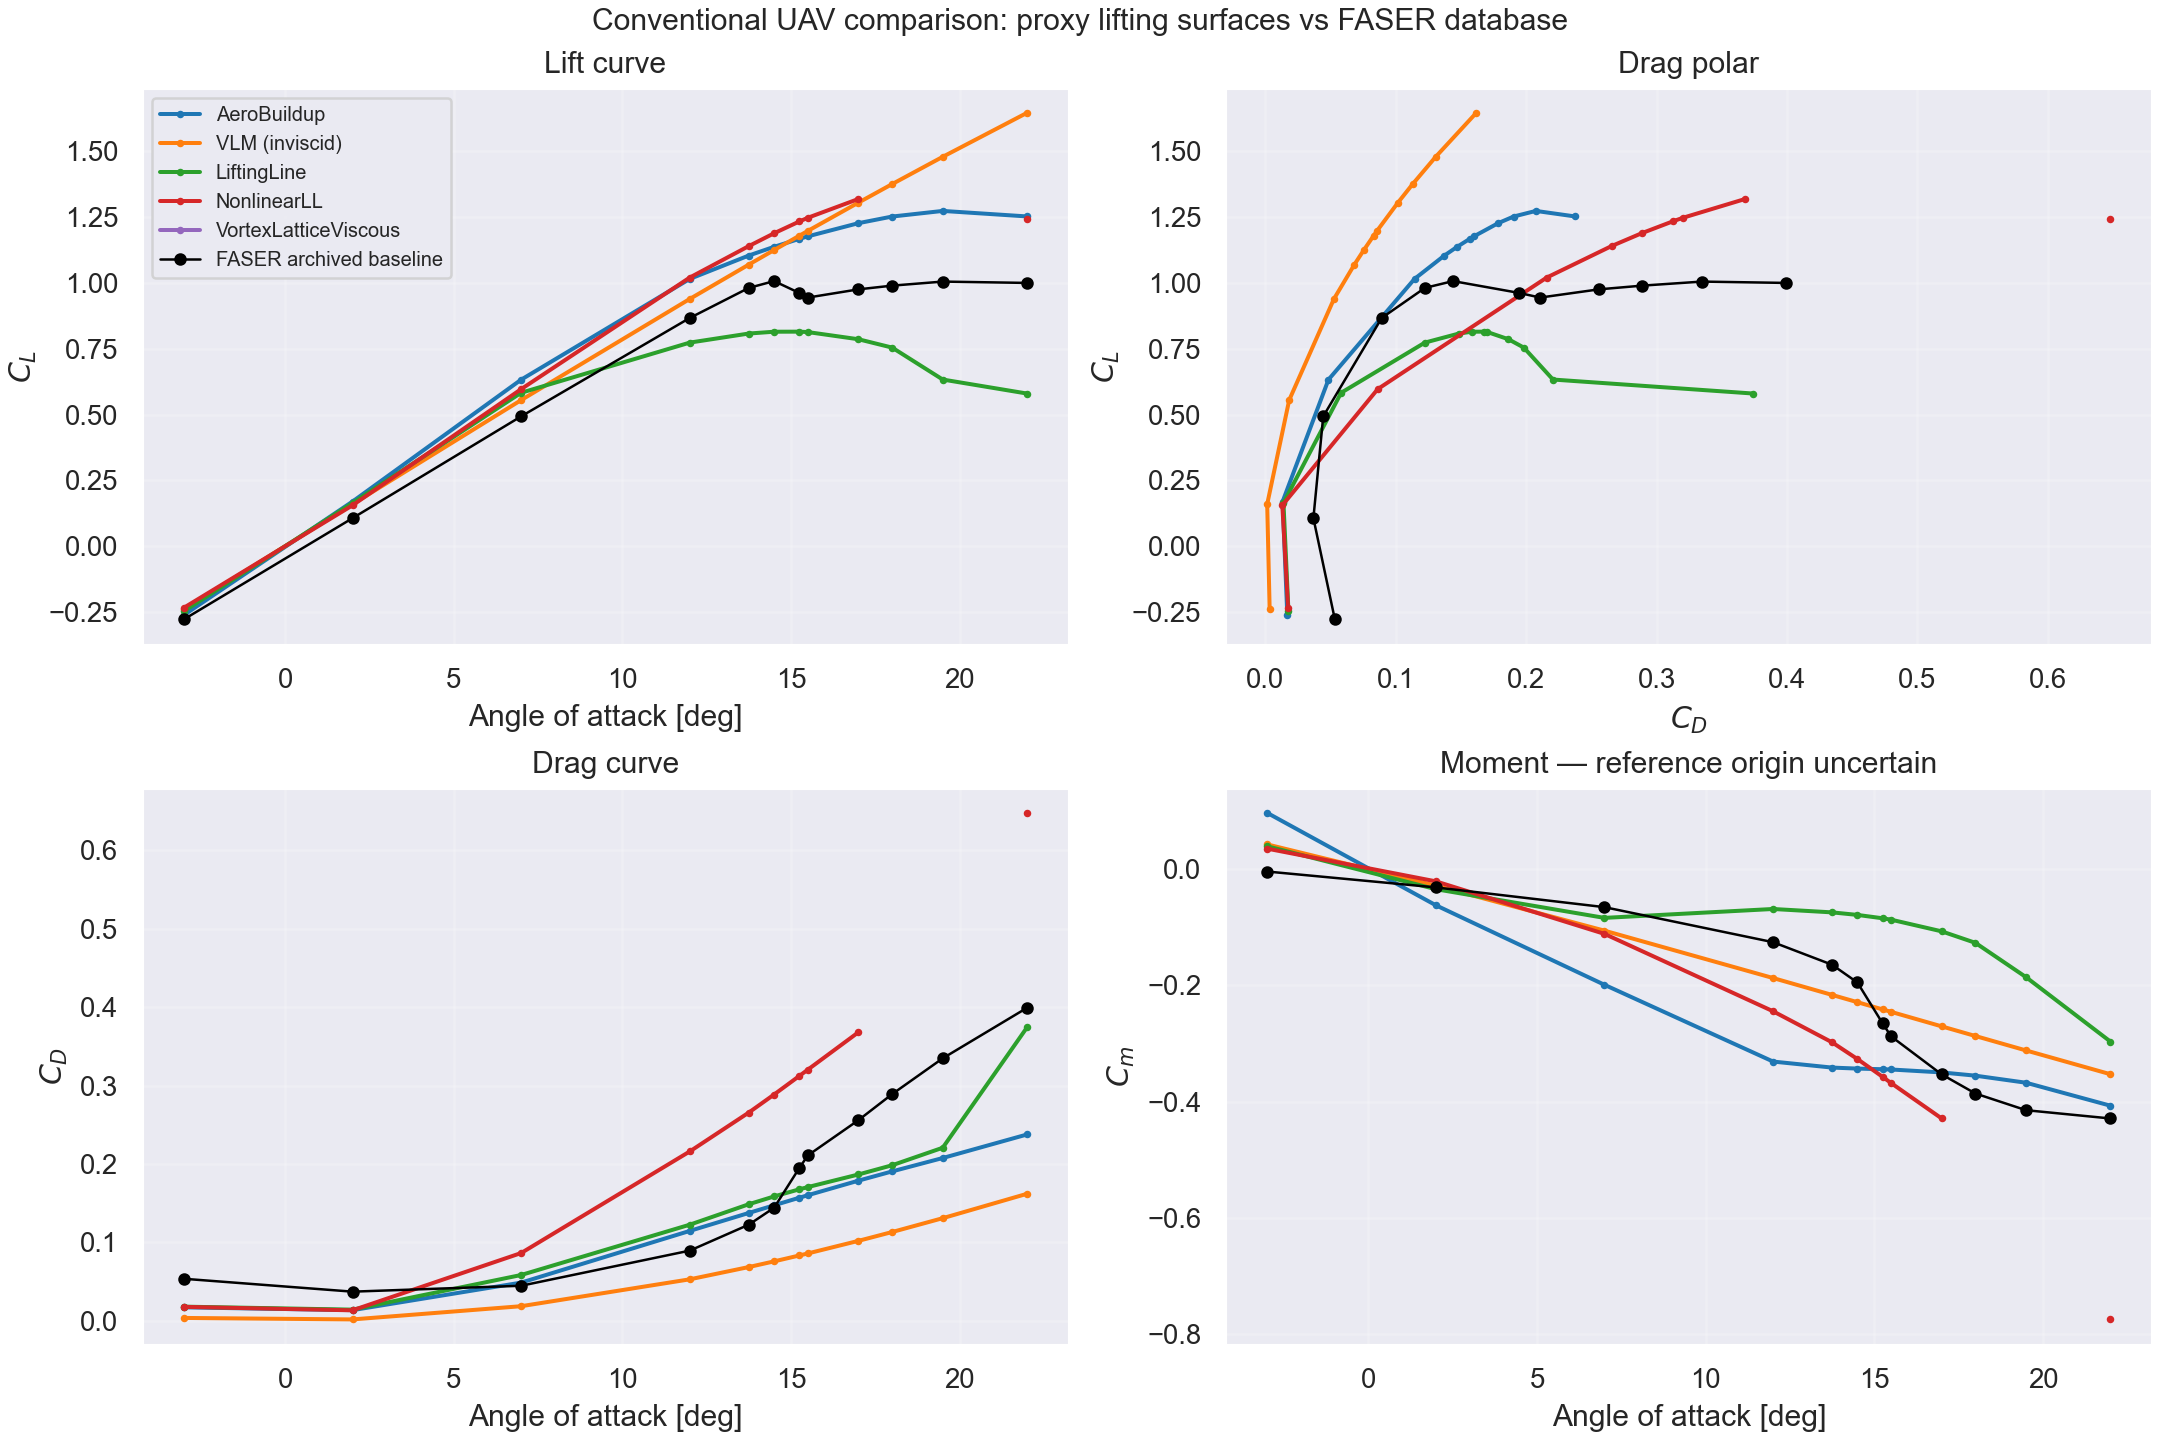

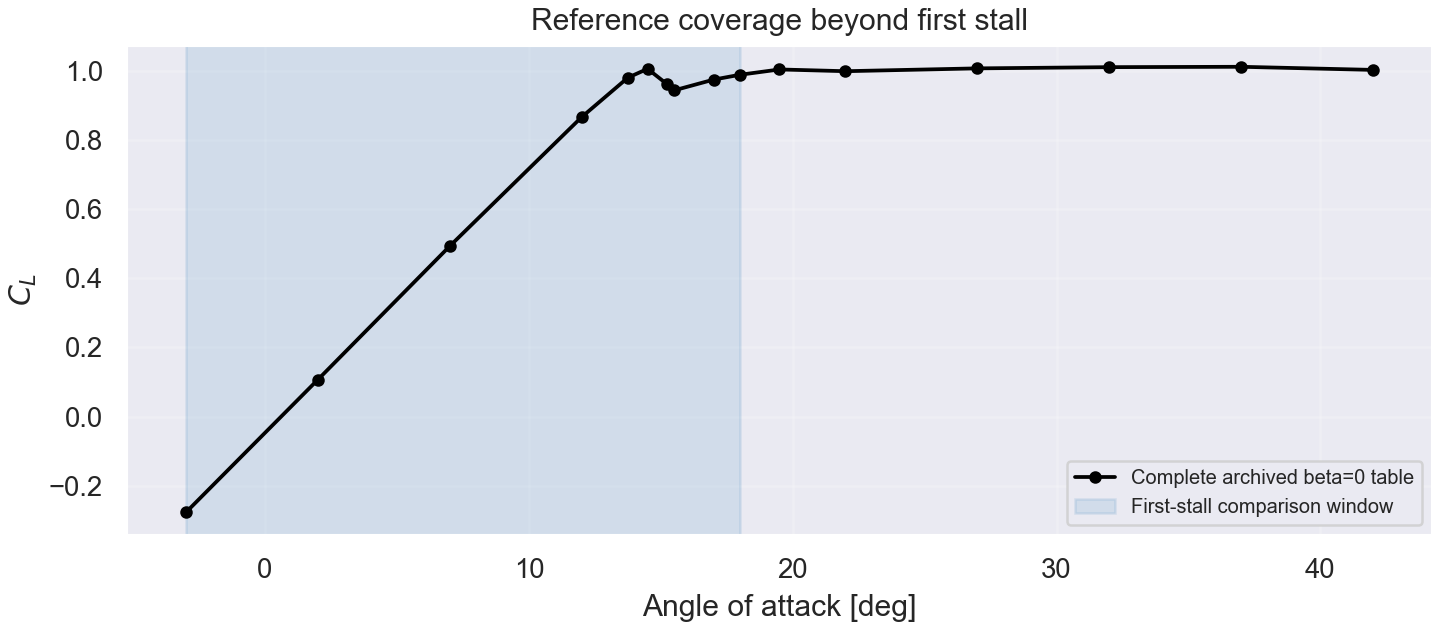

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
colors = dict(zip(methods, plt.get_cmap('tab10').colors))
for method, group in results.groupby('method', sort=False):
    style = dict(color=colors[method], label=method, linewidth=1.6, marker='.', markersize=4)
    axes[0, 0].plot(group.alpha, group.CL, **style)
    axes[0, 1].plot(group.CD, group.CL, **style)
    axes[1, 0].plot(group.alpha, group.CD, **style)
    axes[1, 1].plot(group.alpha, group.Cm, **style)
ref_style = dict(color='black', marker='o', markersize=4, linewidth=1,
                 label='FASER archived baseline')
axes[0, 0].plot(reference_comparison.alpha, reference_comparison.CL, **ref_style)
axes[0, 1].plot(reference_comparison.CD, reference_comparison.CL, **ref_style)
axes[1, 0].plot(reference_comparison.alpha, reference_comparison.CD, **ref_style)
axes[1, 1].plot(reference_comparison.alpha, reference_comparison.Cm, **ref_style)
for ax, title, xlabel, ylabel in [
    (axes[0, 0], 'Lift curve', 'Angle of attack [deg]', '$C_L$'),
    (axes[0, 1], 'Drag polar', '$C_D$', '$C_L$'),
    (axes[1, 0], 'Drag curve', 'Angle of attack [deg]', '$C_D$'),
    (axes[1, 1], 'Moment — reference origin uncertain', 'Angle of attack [deg]', '$C_m$'),
]:
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
axes[0, 0].legend(fontsize=8, loc='upper left')
fig.suptitle('Conventional UAV comparison: proxy lifting surfaces vs FASER database', fontsize=12)
fig.savefig(output_dir / 'conventional_uav_polars.png', dpi=180)
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.5), constrained_layout=True)
ax.plot(reference.alpha, reference.CL, 'ko-', markersize=4, label='Complete archived beta=0 table')
ax.axvspan(-3, 18, alpha=0.12, color='tab:blue', label='First-stall comparison window')
ax.set(xlabel='Angle of attack [deg]', ylabel='$C_L$', title='Reference coverage beyond first stall')
ax.legend(fontsize=8)
fig.savefig(output_dir / 'faser_reference_coverage.png', dpi=180)
plt.show()

## Quantitative comparisons, with bounded stall claims

RMSE is evaluated only at matching archived nodes in −3° ≤ alpha ≤ 12°. It is an **uncalibrated
aircraft-to-proxy discrepancy**, not an isolated solver-error estimate. Failed points do not
enter RMSE and the coverage count must be checked alongside it. Cm errors are omitted.

The second table reports the sampled maximum within −3° ≤ alpha ≤ 18°. It only identifies a
first local peak if both adjacent nodes are available and lower. An endpoint maximum, an
incomplete sweep, or a solver without a stall mechanism is not a CLmax prediction. Even an
interior peak is sampled, with uncertainty from alpha spacing and unknown test conditions.

In [7]:
matched = results.merge(reference_comparison[['alpha', 'CL', 'CD']], on='alpha',
                        suffixes=('', '_reference'), validate='many_to_one')
prestall = matched[matched.alpha.between(-3, 12)]
expected_nodes = int(reference_comparison.alpha.between(-3, 12).sum())
metric_rows = []
for method, group in prestall.groupby('method', sort=False):
    good = group[group.status == 'ok']
    metric_rows.append(dict(
        method=method, coverage=f'{len(good)}/{expected_nodes}',
        CL_RMSE=np.sqrt(np.mean((good.CL - good.CL_reference)**2)) if len(good) else np.nan,
        CD_RMSE=np.sqrt(np.mean((good.CD - good.CD_reference)**2)) if len(good) else np.nan,
    ))
metrics = pd.DataFrame(metric_rows)
metrics.to_csv(output_dir / 'prestall_discrepancies.csv', index=False)
display(metrics)

def sampled_peak(name, frame, allows_stall=True):
    window = frame[frame.alpha.between(-3, 18)].sort_values('alpha')
    finite = np.isfinite(window.CL)
    if not finite.any():
        return dict(method=name, sampled_CL_max=np.nan, alpha_deg=np.nan, interpretation='no solution')
    good = window[finite]
    best = good.loc[good.CL.idxmax()]
    values = window.CL.to_numpy()
    angles = window.alpha.to_numpy()
    j = int(np.flatnonzero(angles == best.alpha)[0])
    interior = 0 < j < len(window) - 1
    local_peak = interior and np.isfinite(values[j-1:j+2]).all() and values[j] > max(values[j-1], values[j+1])
    if not allows_stall:
        interpretation = 'no lift-stall mechanism; not CLmax'
    elif not finite.all():
        interpretation = 'incomplete window; no CLmax claim'
    elif local_peak:
        interpretation = 'sampled interior peak'
    else:
        interpretation = 'no resolved interior peak; not CLmax'
    return dict(method=name, sampled_CL_max=best.CL, alpha_deg=best.alpha, interpretation=interpretation)

peak_rows = [sampled_peak('FASER archived baseline', reference)]
for method, group in results.groupby('method', sort=False):
    peak_rows.append(sampled_peak(method, group, method not in ('VLM (inviscid)', 'VortexLatticeViscous')))
peaks = pd.DataFrame(peak_rows)
peaks.to_csv(output_dir / 'sampled_stall_window_peaks.csv', index=False)
display(peaks)

,method,coverage,CL_RMSE,CD_RMSE
0,AeroBuildup,4/4,0.10683,0.02517
1,VLM (inviscid),4/4,0.05773,0.03800
2,LiftingLine,4/4,0.07264,0.02773
3,NonlinearLL,4/4,0.09819,0.07001
4,VortexLatticeViscous,0/4,NaN,NaN


,method,sampled_CL_max,alpha_deg,interpretation
0,FASER archived baseline,1.00647,14.50000,sampled interior peak
1,AeroBuildup,1.25153,18.00000,no resolved interior peak; not CLmax
2,VLM (inviscid),1.37470,18.00000,no lift-stall mechanism; not CLmax
3,LiftingLine,0.81454,15.25000,sampled interior peak
4,NonlinearLL,1.31822,17.00000,incomplete window; no CLmax claim
5,VortexLatticeViscous,NaN,NaN,no solution


## Mesh sensitivity

Double the spanwise subdivisions, and increase VLM chordwise subdivisions from 5 to 8,
at one attached-flow point and one first-stall point. These are sensitivity checks, not
proof of convergence. AeroBuildup has no panel mesh and is excluded. A nonlinear solve can
also change solution branch near stall; a small panel difference alone does not resolve that.

In [8]:
refinement_rows = []
for method in methods:
    if method == 'AeroBuildup':
        continue
    for alpha in [7.0, 14.5]:
        fine = evaluate(method, alpha, span=2 * SPAN_RESOLUTION, chord=8)
        base = results[(results.method == method) & np.isclose(results.alpha, alpha)].iloc[0]
        refinement_rows.append(dict(
            method=method, alpha=alpha, status=fine['status'], error=fine['error'],
            CL_base=base.CL, CL_refined=fine['CL'], delta_CL=fine['CL'] - base.CL,
            CD_base=base.CD, CD_refined=fine['CD'], delta_CD=fine['CD'] - base.CD,
            seconds=fine['seconds'],
        ))
refinement = pd.DataFrame(refinement_rows)
refinement.to_csv(output_dir / 'mesh_sensitivity.csv', index=False)
display(refinement.drop(columns='error'))
if (refinement.status != 'ok').any():
    display(refinement[refinement.status != 'ok'][['method', 'alpha', 'error']])

CasADi - 2026-11-11 13:00:34 WARNING("solver:nlp_g failed: NaN detected for output g, at (row 48, col 0).") [.../casadi/core/oracle_function.cpp:408]


,method,alpha,status,CL_base,CL_refined,delta_CL,CD_base,CD_refined,delta_CD,seconds
0,VLM (inviscid),7.00000,ok,0.55469,0.54546,-0.00923,0.01839,0.01873,0.00035,0.65716
1,VLM (inviscid),14.50000,ok,1.12426,1.10506,-0.01921,0.07560,0.07704,0.00144,2.18409
2,LiftingLine,7.00000,ok,0.58250,0.56859,-0.01390,0.05822,0.05350,-0.00472,1.68879
3,LiftingLine,14.50000,ok,0.81427,0.79308,-0.02119,0.15846,0.15052,-0.00794,1.47273
4,NonlinearLL,7.00000,failed,0.59632,NaN,NaN,0.08623,NaN,NaN,96.53649
5,NonlinearLL,14.50000,failed,1.18800,NaN,NaN,0.28853,NaN,NaN,92.49660
6,VortexLatticeViscous,7.00000,failed,NaN,NaN,NaN,NaN,NaN,NaN,1.70994
7,VortexLatticeViscous,14.50000,failed,NaN,NaN,NaN,NaN,NaN,NaN,1.60429


,method,alpha,error
4,NonlinearLL,7.00000,"Error in Opti::solve [OptiNode] at .../casadi/core/optistack.cpp:217:\n.../casadi/core/optistack_internal.cpp:1338: Assertion ""return_success(accept_limit)"" failed:\nSolver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Maximum_CpuTime_Exceeded'"
5,NonlinearLL,14.50000,"Error in Opti::solve [OptiNode] at .../casadi/core/optistack.cpp:217:\n.../casadi/core/optistack_internal.cpp:1338: Assertion ""return_success(accept_limit)"" failed:\nSolver failed. You may use opti.debug.value to investigate the latest values of variables. return_status is 'Maximum_CpuTime_Exceeded'"
6,VortexLatticeViscous,7.00000,Nonfinite aerodynamic coefficients
7,VortexLatticeViscous,14.50000,Nonfinite aerodynamic coefficients


## Interpretation and next steps

Use the lift curve to compare onset and shape of nonlinear behavior. Use the pre-stall
error table together with its coverage, and inspect panel sensitivity before interpreting
small differences. Inviscid VLM and the viscous-drag VLM variant do not establish CLmax.
The archived first peak is distinct from the much higher-angle table plateau.

A publishable absolute validation needs the tested article's complete geometry, airfoil
sections and control rigging, the corresponding tunnel conditions/transition treatment,
and an unambiguous moment-reference transformation. Body, landing gear, and installation
effects also need reconciliation. This notebook does not resolve those missing inputs by
fitting offsets. It provides a reproducible conventional-UAV comparison and a source trail
for replacing those assumptions as better documentation becomes available.

All CSVs, plots, source hashes, package versions, solver settings, and run status are saved
next to the source assets. Re-running the notebook recomputes predictions; it never loads a
cached solver answer as a new calculation.

In [9]:
repo_root = _REPOSITORY_ROOT
def git_text(*args):
    command = subprocess.run(['git', '-C', str(repo_root), *args], capture_output=True, text=True)
    return command.stdout.strip() if command.returncode == 0 else 'unavailable'

environment = {
    'python': platform.python_version(),
    'thread_environment': {name: os.environ.get(name) for name in
                           ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS']},
    'packages': {name: importlib.metadata.version(name)
                 for name in ['AeroSandbox', 'numpy', 'scipy', 'pandas', 'matplotlib', 'neuralfoil', 'casadi']},
    'aerosandbox_import_path': str(Path(asb.__file__).resolve()),
    'git_head': git_text('rev-parse', 'HEAD'),
    'tracked_changes': git_text('status', '--short', '--untracked-files=no'),
    'source_hashes': {name: entry['sha256'] for name, entry in sources['files'].items()},
    'settings': {'velocity_m_s': VELOCITY, 'q_Pa': Q_REF_PA, 'altitude_m': 0,
                 'S_m2': S_REF, 'b_m': B_REF, 'c_m': C_REF, 'xyz_ref_m': XYZ_REF,
                 'alpha_deg': ALPHAS.tolist(), 'spanwise_resolution': SPAN_RESOLUTION,
                 'chordwise_resolution': CHORD_RESOLUTION,
                 'nonlinear_solver': {'max_iter': 200, 'max_runtime_s': 45,
                                      'hessian_approximation': 'limited-memory',
                                      'initialization': 'previous successful circulation, ascending alpha'},
                 'scope': 'lifting surfaces only; no fitted offsets; proxy geometry'},
    'successes': int((results.status == 'ok').sum()),
    'failures': int((results.status != 'ok').sum()),
}
(output_dir / 'run_metadata.json').write_text(json.dumps(environment, indent=2) + '\n')
print(f'Saved {environment["successes"]} successful and {environment["failures"]} failed evaluations.')
print('Result files:', ', '.join(p.name for p in sorted(output_dir.iterdir()) if p.is_file()))

Saved 46 successful and 14 failed evaluations.
Result files: conventional_uav_geometry.png, conventional_uav_polars.png, conventional_uav_predictions.csv, faser_reference_beta0.csv, faser_reference_coverage.png, mesh_sensitivity.csv, prestall_discrepancies.csv, run_metadata.json, sampled_stall_window_peaks.csv


## Diagnose the vertical-fin limitation

On the recorded checkout, VortexLatticeViscous returned nonfinite whole-aircraft coefficients
at every main-sweep node. The current VLM `spanwise_cl` is defined using projected-y strip
width; a vertical fin has zero projected-y width, so that sectional quantity is NaN even
though VLM's integrated forces are finite. The viscous closure consumes that quantity and
propagates the NaN into its total forces. This is a limitation of the current branch's strip
closure, separate from the experimental-data mismatch.

The diagnostic below compares the complete lifting-surface model with a **different,
wing-and-horizontal-tail-only model** at two angles. It checks whether removing the fin
restores finite viscous results. These diagnostic answers are kept separate from the main
comparison and its error metrics; they are not substituted for failed full-aircraft nodes.
The AeroSandbox library is unchanged by this study.

In [10]:
diagnostic_plane = asb.Airplane(
    name='Ultra Stick wing and horizontal tail diagnostic', xyz_ref=XYZ_REF,
    wings=[main_wing, horizontal_tail], s_ref=S_REF, b_ref=B_REF, c_ref=C_REF,
)
diagnostic_rows = []
for alpha in [7.0, 14.5]:
    cases = [
        ('Full lifting surfaces', 'VLM', asb.VortexLatticeMethod, airplane),
        ('Wing + horizontal tail only', 'VLM', asb.VortexLatticeMethod, diagnostic_plane),
    ]
    if hasattr(asb, 'VortexLatticeViscous'):
        cases.append(('Wing + horizontal tail only', 'VortexLatticeViscous',
                      asb.VortexLatticeViscous, diagnostic_plane))
    for scope, method, solver, geometry in cases:
        aero = solver(airplane=geometry, op_point=operating_point(alpha),
                      spanwise_resolution=SPAN_RESOLUTION,
                      chordwise_resolution=CHORD_RESOLUTION).run()
        values = {key: float(np.asarray(aero[key]).squeeze()) for key in ['CL', 'CD', 'Cm']}
        assert np.isfinite(list(values.values())).all(), f'{method}: {scope} is nonfinite'
        diagnostic_rows.append(dict(
            alpha=alpha, scope=scope, method=method, **values,
            nonfinite_sectional_cl=int((~np.isfinite(np.asarray(aero['spanwise_cl']))).sum()),
        ))
fin_diagnostic = pd.DataFrame(diagnostic_rows)
fin_diagnostic.to_csv(output_dir / 'vertical_fin_diagnostic.csv', index=False)
display(fin_diagnostic)
print('Diagnostic saved separately; main comparison retains its full-aircraft failure records.')

Diagnostic saved separately; main comparison retains its full-aircraft failure records.


,alpha,scope,method,CL,CD,Cm,nonfinite_sectional_cl
0,7.0,Full lifting surfaces,VLM,0.55469,0.01839,-0.10653,3
1,7.0,Wing + horizontal tail only,VLM,0.55469,0.01839,-0.10653,0
2,7.0,Wing + horizontal tail only,VortexLatticeViscous,0.55469,0.03240,-0.10552,0
3,14.5,Full lifting surfaces,VLM,1.12426,0.07560,-0.22939,3
4,14.5,Wing + horizontal tail only,VLM,1.12426,0.07560,-0.22939,0
5,14.5,Wing + horizontal tail only,VortexLatticeViscous,1.12426,0.10907,-0.22883,0


The saved diagnostic has finite VortexLatticeViscous results after the vertical fin is
removed. A general fix needs a sectional coefficient based on the force and span appropriate
to each surface orientation, rather than feeding a projected-y lift distribution into every
airfoil closure. That change belongs in a separately reviewed library contribution.

NonlinearLL's main sweep also has two rejected nodes: at 18 degrees its residual exceeded
the study's 1e-5 acceptance threshold; at 19.5 degrees IPOPT did not converge within the
configured limits. The later finite 22-degree result does not resolve branch uniqueness or
make the missing interval a validated stall prediction. Read the CSV error messages and
mesh sensitivity alongside the polar plots.